# RQ7 & RQ8: Housing Buildings, Housing Projects and Serious Crashes

**RQ7:** Is a higher number of housing buildings associated with more severe injuries? *(Scatter plot)*

**RQ8:** Which boroughs have the highest number of serious crashes per housing project? *(Bar chart)*

Both questions use `df_integrated`: one row per `zip_code` + `year` (2022–2026), built by aggregating the
Affordable Housing Production by Building dataset (`hg8x-zxpr`) and the SIRTA serious-injury crash dataset
(`xeqp-qz8h`) before merging. The same two visualizations appear on the website, where they respond to the
borough, ZIP code, year and transportation filters.

## Setup: load `df_integrated`
The notebook reads `df_integrated.csv` from the repository root. In Google Colab, upload the file first.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

df_integrated = pd.read_csv("df_integrated.csv")

BOROUGH_COLORS = {
    "Manhattan": "#2a6fdb", "Brooklyn": "#e0702b", "Queens": "#2f9e6e",
    "Bronx": "#c43d5a", "Staten Island": "#7d5bbe",
}

print("Shape:", df_integrated.shape)
print("Years:", sorted(df_integrated["year"].unique().tolist()))
print("ZIP codes:", df_integrated["zip_code"].nunique())
print("Missing values:", int(df_integrated.isna().sum().sum()))
print("Duplicate zip_code + year rows:", int(df_integrated.duplicated(["zip_code", "year"]).sum()))

Shape: (484, 11)
Years: [2022, 2023, 2024, 2025, 2026]
ZIP codes: 143
Missing values: 0
Duplicate zip_code + year rows: 0


### Data checks before answering
- `df_integrated` has **no missing values** and **no duplicate `zip_code` + `year` rows**, so nothing needs
  to be filled or dropped for these two questions.
- **2022 and 2026 are partial years** (far fewer crashes than the full years 2023–2025, see the table
  below). Totals over 2022–2026 are therefore not five full years. Each result below is repeated on the
  full years **2023–2025** to check that it does not depend on the partial years.
- The integration used an **inner join**, so only ZIP-years that have both housing records and crash
  records are included. Crashes in ZIP-years with no affordable housing activity are not counted.

In [2]:
df_integrated.groupby("year").agg(
    zip_codes=("zip_code", "nunique"),
    housing_buildings=("housing_building_count", "sum"),
    housing_projects=("housing_project_count", "sum"),
    serious_crashes=("serious_crash_count", "sum"),
    severe_injuries=("severe_injuries", "sum"),
)

,zip_codes,housing_buildings,housing_projects,serious_crashes,severe_injuries
year,,,,,
2022,91,449.0,367.0,339.0,338.0
2023,104,716.0,532.0,1553.0,1549.0
2024,102,718.0,442.0,1597.0,1601.0
2025,110,600.0,441.0,1846.0,1886.0
2026,77,390.0,249.0,546.0,566.0


## RQ7: Is a higher number of housing buildings associated with more severe injuries?

**Approach.** For each ZIP code we total the housing buildings (`housing_building_count`) and the severe
injuries (`severe_injuries`) across the years, then plot one point per ZIP code.

- **Why ZIP code totals:** a single ZIP-year has very few buildings and injuries (median 3 buildings and
  10 severe injuries), so year-by-year points are noisy. Totals per ZIP code give a clearer picture of
  which areas are high or low on both.
- **Why a scatter plot:** both variables are numeric, and a scatter plot shows the direction and strength
  of the relationship, plus the ZIP codes that break the pattern. Points are coloured by borough.
- **Statistics:** Pearson *r* measures the linear relationship. Spearman *ρ* uses ranks, so it is less
  affected by a few ZIP codes with very many buildings. We report both.

In [3]:
def zip_totals(data):
    """Total housing buildings and severe injuries per ZIP code."""
    return (data.groupby(["zip_code", "borough"], as_index=False)
                .agg(housing_buildings=("housing_building_count", "sum"),
                     severe_injuries=("severe_injuries", "sum")))

def correlation_summary(zips, label):
    r, p_r = stats.pearsonr(zips["housing_buildings"], zips["severe_injuries"])
    rho, p_rho = stats.spearmanr(zips["housing_buildings"], zips["severe_injuries"])
    print(f"{label}: {len(zips)} ZIP codes | Pearson r = {r:.2f} (p = {p_r:.1e}) | "
          f"Spearman rho = {rho:.2f} (p = {p_rho:.1e})")
    return r

rq7 = zip_totals(df_integrated)
r_all = correlation_summary(rq7, "2022-2026")
r_full_years = correlation_summary(
    zip_totals(df_integrated[df_integrated["year"].between(2023, 2025)]),
    "2023-2025 (full years only)")

2022-2026: 143 ZIP codes | Pearson r = 0.63 (p = 3.2e-17) | Spearman rho = 0.73 (p = 5.2e-25)
2023-2025 (full years only): 134 ZIP codes | Pearson r = 0.57 (p = 4.9e-13) | Spearman rho = 0.70 (p = 3.0e-21)


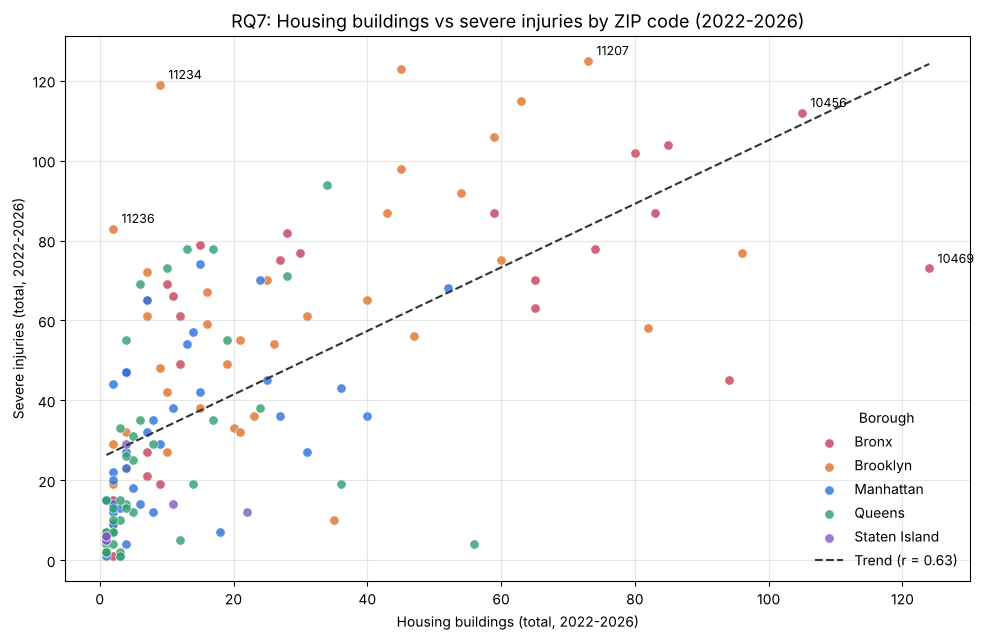

In [4]:
fig, ax = plt.subplots(figsize=(10, 6.5))
for borough, group in rq7.groupby("borough"):
    ax.scatter(group["housing_buildings"], group["severe_injuries"], s=45, alpha=0.8,
               color=BOROUGH_COLORS[borough], label=borough, edgecolor="white", linewidth=0.5)

# Least-squares trendline
slope, intercept = np.polyfit(rq7["housing_buildings"], rq7["severe_injuries"], 1)
xs = np.linspace(rq7["housing_buildings"].min(), rq7["housing_buildings"].max(), 50)
ax.plot(xs, slope * xs + intercept, "--", color="#333", label=f"Trend (r = {r_all:.2f})")

# Label the ZIP codes discussed in the analysis
for z in [10469, 10456, 11207, 11234, 11236]:
    row = rq7[rq7["zip_code"] == z].iloc[0]
    ax.annotate(str(z), (row["housing_buildings"], row["severe_injuries"]),
                xytext=(6, 4), textcoords="offset points", fontsize=9)

ax.set_title("RQ7: Housing buildings vs severe injuries by ZIP code (2022-2026)", fontsize=13)
ax.set_xlabel("Housing buildings (total, 2022-2026)")
ax.set_ylabel("Severe injuries (total, 2022-2026)")
ax.legend(title="Borough", frameon=False)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**ZIP codes with the most housing buildings:**

In [5]:
cols = ["zip_code", "borough", "housing_buildings", "severe_injuries"]
rq7.nlargest(5, "housing_buildings")[cols]

,zip_code,borough,housing_buildings,severe_injuries
59,10469,Bronx,124.0,73.0
48,10456,Bronx,105.0,112.0
80,11210,Brooklyn,96.0,77.0
44,10452,Bronx,94.0,45.0
49,10457,Bronx,85.0,104.0


**ZIP codes with the most severe injuries:**

In [6]:
rq7.nlargest(5, "severe_injuries")[cols]

,zip_code,borough,housing_buildings,severe_injuries
77,11207,Brooklyn,73.0,125.0
73,11203,Brooklyn,45.0,123.0
102,11234,Brooklyn,9.0,119.0
82,11212,Brooklyn,63.0,115.0
48,10456,Bronx,105.0,112.0


**Many severe injuries with 10 or fewer housing buildings:**

In [7]:
rq7[rq7["housing_buildings"] <= 10].nlargest(3, "severe_injuries")[cols]

,zip_code,borough,housing_buildings,severe_injuries
102,11234,Brooklyn,9.0,119.0
104,11236,Brooklyn,2.0,83.0
110,11355,Queens,10.0,73.0


### RQ7: Findings
- **Result:** across 143 ZIP codes there is a **moderate-to-strong positive association** between housing
  buildings and severe injuries (Pearson *r* = 0.63, Spearman *ρ* = 0.73, both p < 0.001). ZIP codes with
  more affordable housing buildings tend to also record more severe injuries.
- **Robustness:** using only the full years 2023–2025 gives a similar result (*r* = 0.57, *ρ* = 0.70 over
  134 ZIP codes), so the pattern is not caused by the partial years.
- **High on both:** Bronx ZIP codes **10469** (124 buildings, 73 severe injuries) and **10456** (105
  buildings, 112 severe injuries) lead in housing buildings and are also among the highest for injuries.
- **Exceptions:** Brooklyn **11234** has only 9 housing buildings but 119 severe injuries, the third
  highest in the city, and **11236** has 2 buildings but 83 injuries. In these areas, road danger is not
  explained by housing activity. Major roads and traffic volume are likely factors.
- **Interpretation:** this is an **association, not causation**. ZIP codes that are larger, denser or
  busier can have both more construction and more traffic, so both counts rise together. The data does
  not include population, area or traffic volume, so we cannot separate these effects.

## RQ8: Which boroughs have the highest number of serious crashes per housing project?

**Approach.** For each borough we divide the total serious crashes (`serious_crash_count`) by the total
housing projects (`housing_project_count`).

- **Why a ratio:** raw totals favour large boroughs. Dividing by housing projects shows how much
  serious-crash activity there is relative to the amount of affordable housing development.
- **Why a bar chart:** it compares one number across five categories, and sorting the bars makes the
  ranking easy to read.
- **Division by zero:** every borough has housing projects, so no borough is dropped. The website still
  checks for zero projects, because some filter combinations could produce it.

**Serious crashes per housing project, 2022-2026:**

In [8]:
def borough_ratio(data):
    out = (data.groupby("borough", as_index=False)
               .agg(serious_crashes=("serious_crash_count", "sum"),
                    housing_projects=("housing_project_count", "sum"),
                    zip_codes=("zip_code", "nunique")))
    out = out[out["housing_projects"] > 0].copy()
    out["crashes_per_project"] = out["serious_crashes"] / out["housing_projects"]
    return out.sort_values("crashes_per_project", ascending=False).reset_index(drop=True)

rq8 = borough_ratio(df_integrated)
rq8.round(2)

,borough,serious_crashes,housing_projects,zip_codes,crashes_per_project
0,Staten Island,83.0,15.0,7,5.53
1,Manhattan,1121.0,256.0,36,4.38
2,Queens,1009.0,275.0,40,3.67
3,Brooklyn,2257.0,756.0,37,2.99
4,Bronx,1411.0,729.0,23,1.94


**Same ratio using only the full years 2023-2025:**

In [9]:
rq8_full_years = borough_ratio(df_integrated[df_integrated["year"].between(2023, 2025)])
rq8_full_years.round(2)

,borough,serious_crashes,housing_projects,zip_codes,crashes_per_project
0,Staten Island,77.0,13.0,7,5.92
1,Manhattan,962.0,178.0,34,5.40
2,Queens,874.0,193.0,34,4.53
3,Brooklyn,1916.0,520.0,37,3.68
4,Bronx,1167.0,511.0,22,2.28


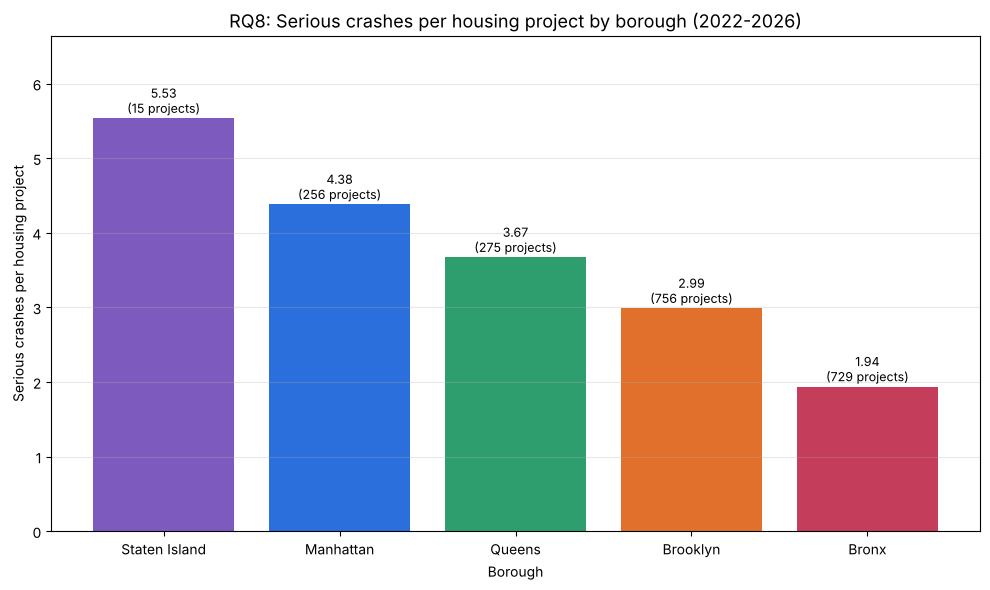

In [10]:
fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar(rq8["borough"], rq8["crashes_per_project"],
              color=[BOROUGH_COLORS[b] for b in rq8["borough"]])
for bar, (_, row) in zip(bars, rq8.iterrows()):
    ax.annotate(f"{row['crashes_per_project']:.2f}\n({int(row['housing_projects'])} projects)",
                (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                xytext=(0, 4), textcoords="offset points", ha="center", fontsize=9)

ax.set_title("RQ8: Serious crashes per housing project by borough (2022-2026)", fontsize=13)
ax.set_xlabel("Borough")
ax.set_ylabel("Serious crashes per housing project")
ax.set_ylim(0, rq8["crashes_per_project"].max() * 1.2)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### RQ8: Findings
- **Ranking:** **Staten Island** has the most serious crashes per housing project (5.53), followed by
  **Manhattan** (4.38), **Queens** (3.67) and **Brooklyn** (2.99). The **Bronx** has the fewest (1.94).
- **Same order on full years:** using only 2023–2025 gives the same ranking (Staten Island 5.92,
  Manhattan 5.40, Queens 4.53, Brooklyn 3.68, Bronx 2.28).
- **Bronx vs Brooklyn:** both build a lot of affordable housing (729 and 756 projects), but the Bronx has
  far fewer serious crashes per project. In the Bronx, housing growth is less matched by serious-crash
  activity.
- **Caution on Staten Island:** its ratio rests on only **15 housing projects** across 7 ZIP codes, so a
  few extra crashes or projects would change it a lot. It is the least reliable of the five values.
- **Interpretation:** a high ratio does **not** mean housing projects cause crashes, or that one borough is
  more dangerous per person. The ratio only compares crash activity with housing development. It does not
  account for population, road length or traffic volume.

## Limitations
- **Aggregation level:** data is aggregated to ZIP code and year, so patterns inside a ZIP code (a
  specific street or intersection) are not visible.
- **Inner join:** only ZIP-years with both housing and crash records are included, so crash totals are
  lower than citywide totals.
- **Partial years:** 2022 and 2026 are incomplete. Both results were checked on 2023–2025.
- **Missing context:** there are no population, area or traffic-volume figures, so the results cannot be
  expressed per resident or per vehicle.
- **Association only:** neither question shows that housing development causes crashes or injuries.


All numbers above come from running the code in this notebook on `df_integrated.csv`.